In [1]:
# Standard library imports
import os
import sqlite3
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

## Notebook Presets


#### Chart Presets

Every chart in this notebook is drawn through the helper functions defined in the next cell. To restyle all charts at once, change the values in the `PRESETS` dictionary (colours, fonts, sizes, label formats) and re-run that one cell, then re-run the chart cells.

| Setting | What it controls |
|---|---|
| `colors` | Main bar colour, highlight colour for top items, reference lines, text and grid colours |
| `categorical` | Colours used when points are grouped (for example product lines) |
| `fonts` | Title, subtitle, axis label, tick and annotation sizes |
| `sizes` | Default figure sizes for each chart type, bar width, point sizes |
| `highlight_top` | How many of the top bars get the highlight colour |
| `save_charts` | Set to `True` to also save each chart as a PNG in the `charts/` folder |


In [ ]:
PRESETS = {
    "colors": {
        "primary":   "#2A6F97",
        "highlight": "#E07A1F",
        "reference": "#D1495B",
        "text":      "#1F2933",
        "muted":     "#6B7785",
        "grid":      "#E4E7EB",
        "background": "#FFFFFF",
    },
    "categorical": ["#2A6F97", "#E07A1F", "#3A9D8F", "#8E6BBF",
                    "#D1495B", "#C9A227", "#4F6D7A", "#7BA05B"],
    "fonts": {
        "family": "DejaVu Sans",
        "title": 16, "subtitle": 12, "label": 10, "tick": 10, "annotation": 9,
    },
    "sizes": {
        "bar_vertical":   (11, 6),
        "bar_horizontal": (11, 6.5),
        "scatter":        (10.5, 6.5),
        "bar_width": 0.72,
        "point_min": 90, "point_max": 650, "point_default": 220,
    },
    "highlight_top": 3,
    "show_value_labels": True,
    "save_charts": False,
    "output_dir": "charts",
}

def money(v, pos=None):
    """$1,234 style label (also used by tick formatters)."""
    return f"${v:,.0f}"

def thousands(v, pos=None):
    """1,234 style label."""
    return f"{v:,.0f}"

def apply_theme():
    """Apply the PRESETS look globally through matplotlib (plt) settings."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    plt.style.use("default")
    plt.rcParams.update({
        "font.family": f["family"],
        "axes.prop_cycle": plt.cycler(color=PRESETS["categorical"]),
        "figure.facecolor": c["background"], "axes.facecolor": c["background"],
        "axes.edgecolor": c["grid"], "axes.labelcolor": c["text"],
        "axes.labelsize": f["label"], "axes.titlesize": f["title"],
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "xtick.color": c["muted"], "ytick.color": c["muted"],
        "xtick.labelsize": f["tick"], "ytick.labelsize": f["tick"],
        "grid.color": c["grid"], "grid.linewidth": 0.9,
        "text.color": c["text"], "legend.frameon": False,
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    })

def finish_chart(ax, title, xlabel, ylabel, subtitle=None,
                 x_fmt=None, y_fmt=None, grid_axis="y"):
    """Titles, labels, clean spines, formatters and gridlines in one place."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    fig = ax.figure
    ax.set_title(title, loc="left", fontsize=f["title"], fontweight="bold",
                 color=c["text"], pad=30 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=f["subtitle"],
                color=c["muted"], va="bottom", ha="left")
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel(ylabel, labelpad=10)
    if x_fmt: ax.xaxis.set_major_formatter(mtick.FuncFormatter(x_fmt))
    if y_fmt: ax.yaxis.set_major_formatter(mtick.FuncFormatter(y_fmt))
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.grid(False)
    if grid_axis in ("x", "y"):
        ax.grid(axis=grid_axis, color=c["grid"])
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    fig.tight_layout()
    return ax

def add_value_labels(ax, fmt=thousands, horizontal=False, pad=4):
    """Write each bar's value at its tip."""
    if not PRESETS["show_value_labels"]:
        return
    c, f = PRESETS["colors"], PRESETS["fonts"]
    for p in ax.patches:
        size = p.get_width() if horizontal else p.get_height()
        if not np.isfinite(size) or size == 0:
            continue
        if horizontal:
            ax.annotate(fmt(size), (p.get_width(), p.get_y() + p.get_height() / 2),
                        xytext=(pad, 0), textcoords="offset points", va="center",
                        fontsize=f["annotation"], color=c["text"], bbox=dict(boxstyle="round,pad=0.15", fc=c["background"], ec="none", alpha=0.9))
        else:
            ax.annotate(fmt(size), (p.get_x() + p.get_width() / 2, p.get_height()),
                        xytext=(0, pad), textcoords="offset points", ha="center",
                        fontsize=f["annotation"], color=c["text"],
                        bbox=dict(boxstyle="round,pad=0.15", fc=c["background"], ec="none", alpha=0.9))

def add_reference_line(ax, value, label, horizontal=True):
    """Dashed reference line (e.g. an average) with a legend entry."""
    c = PRESETS["colors"]
    line = ax.axhline if horizontal else ax.axvline
    line(value, color=c["reference"], linestyle="--", linewidth=1.6, label=label)
    ax.legend(loc="upper right")

def save_chart(fig, name):
    """Save a PNG when PRESETS['save_charts'] is True."""
    if PRESETS["save_charts"]:
        os.makedirs(PRESETS["output_dir"], exist_ok=True)
        fig.savefig(os.path.join(PRESETS["output_dir"], f"{name}.png"))

def _bar_palette(categories):
    c = PRESETS["colors"]
    n = PRESETS["highlight_top"]
    return {cat: (c["highlight"] if i < n else c["primary"])
            for i, cat in enumerate(categories)}

def bar_chart(df, x, y, title, xlabel, ylabel, subtitle=None, value_fmt=money,
              axis_fmt=money, ref_line=None, ref_label=None, name="bar_chart"):
    """Vertical bar chart. Rows should already be sorted; the first
    PRESETS['highlight_top'] bars are highlighted."""
    fig, ax = plt.subplots(figsize=PRESETS["sizes"]["bar_vertical"])
    order = list(df[x])
    sns.barplot(data=df, x=x, y=y, hue=x, order=order, palette=_bar_palette(order),
                width=PRESETS["sizes"]["bar_width"], legend=False, ax=ax)
    add_value_labels(ax, fmt=value_fmt)
    if ref_line is not None:
        add_reference_line(ax, ref_line, ref_label)
    ax.margins(y=0.12)
    finish_chart(ax, title, xlabel, ylabel, subtitle, y_fmt=axis_fmt, grid_axis="y")
    save_chart(fig, name)
    plt.show()
    return ax

def hbar_chart(df, x, y, title, xlabel, ylabel, subtitle=None, value_fmt=money,
               axis_fmt=money, name="hbar_chart"):
    """Horizontal ranked bar chart (largest at the top)."""
    fig, ax = plt.subplots(figsize=PRESETS["sizes"]["bar_horizontal"])
    order = list(df.sort_values(x, ascending=False)[y])
    sns.barplot(data=df, x=x, y=y, hue=y, order=order, palette=_bar_palette(order),
                width=PRESETS["sizes"]["bar_width"], orient="h", legend=False, ax=ax)
    add_value_labels(ax, fmt=value_fmt, horizontal=True)
    ax.margins(x=0.14)
    finish_chart(ax, title, xlabel, ylabel, subtitle, x_fmt=axis_fmt, grid_axis="x")
    save_chart(fig, name)
    plt.show()
    return ax

def place_point_labels(ax, xs, ys, labels, radii_pt):
    """Label every point without overlaps. For each point several label positions are tried
    (right, left, above, below, further out) and the first one that does not collide with
    another label, another point or the figure edge is kept."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer() if hasattr(fig.canvas, "get_renderer") else fig._get_renderer()
    px_per_pt = fig.dpi / 72
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    options = [(1, 0, "left", "center"), (-1, 0, "right", "center"),
               (0, 1.2, "center", "bottom"), (0, -1.2, "center", "top"),
               (1, 0.9, "left", "bottom"), (1, -0.9, "left", "top"),
               (-1, 0.9, "right", "bottom"), (-1, -0.9, "right", "top"),
               (1, 2.4, "left", "bottom"), (1, -2.4, "left", "top"),
               (-1, 2.4, "right", "bottom"), (-1, -2.4, "right", "top")]
    leader = dict(arrowstyle="-", color=c["muted"], lw=0.7, shrinkA=0, shrinkB=0)

    def hits_marker(bb, j):
        cx, cy = pts[j]
        dx = max(bb.x0 - cx, 0, cx - bb.x1)
        dy = max(bb.y0 - cy, 0, cy - bb.y1)
        return (dx * dx + dy * dy) < (radii_pt[j] * px_per_pt) ** 2

    placed = []
    for i in np.argsort(-pts[:, 1]):
        step = radii_pt[i] + 4
        chosen = None
        for n_opt, (kx, ky, ha, va) in enumerate(options):
            t = ax.annotate(labels[i], (xs[i], ys[i]), xytext=(kx * step, ky * step),
                            textcoords="offset points", ha=ha, va=va,
                            fontsize=f["annotation"], color=c["text"],
                            arrowprops=leader if n_opt >= 8 else None)
            bb = t.get_window_extent(renderer).expanded(1.04, 1.15)
            inside = (fig.bbox.x0 <= bb.x0 and bb.x1 <= fig.bbox.x1 and
                      fig.bbox.y0 <= bb.y0 and bb.y1 <= fig.bbox.y1)
            clash = any(bb.overlaps(p) for p in placed) or any(hits_marker(bb, j) for j in range(len(xs)) if j != i)
            if inside and not clash:
                chosen = bb
                break
            t.remove()
        if chosen is None:
            kx, ky, ha, va = options[0]
            t = ax.annotate(labels[i], (xs[i], ys[i]), xytext=(kx * step, ky * step),
                            textcoords="offset points", ha=ha, va=va,
                            fontsize=f["annotation"], color=c["text"])
            chosen = t.get_window_extent(renderer)
        placed.append(chosen)

def labeled_scatter(df, x, y, label, title, xlabel, ylabel, subtitle=None,
                    size=None, color_by=None, x_fmt=None, y_fmt=None,
                    median_lines=True, name="scatter"):
    """Scatter plot where every point is labelled; optional bubble size and
    median guide lines that split the chart into four readable quadrants."""
    c, f, s = PRESETS["colors"], PRESETS["fonts"], PRESETS["sizes"]
    fig, ax = plt.subplots(figsize=s["scatter"])
    kwargs = dict(data=df, x=x, y=y, alpha=0.85, edgecolor="white", linewidth=1.2, ax=ax)
    if size:
        kwargs.update(size=size, sizes=(s["point_min"], s["point_max"]), legend=False)
    else:
        kwargs.update(s=s["point_default"], legend=False)
    if color_by:
        kwargs.update(hue=color_by, palette=PRESETS["categorical"][:df[color_by].nunique()])
    else:
        kwargs.update(color=c["primary"])
    sns.scatterplot(**kwargs)
    if median_lines:
        ax.axvline(df[x].median(), color=c["muted"], linestyle=":", linewidth=1.2)
        ax.axhline(df[y].median(), color=c["muted"], linestyle=":", linewidth=1.2,
                   label="Median guides")
    ax.margins(x=0.12, y=0.14)
    finish_chart(ax, title, xlabel, ylabel, subtitle, x_fmt=x_fmt, y_fmt=y_fmt, grid_axis="both")
    ax.grid(axis="both", color=c["grid"])
    if size:
        span = (df[size].max() - df[size].min()) or 1
        areas = s["point_min"] + (df[size] - df[size].min()) / span * (s["point_max"] - s["point_min"])
    else:
        areas = np.full(len(df), s["point_default"], dtype=float)
    place_point_labels(ax, df[x].to_numpy(), df[y].to_numpy(), df[label].astype(str).to_numpy(),
                       np.sqrt(np.asarray(areas, dtype=float)) / 2)
    save_chart(fig, name)
    plt.show()
    return ax

apply_theme()
print("Chart presets loaded.")

Chart presets loaded.


# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [ ]:
# create connection
conn = sqlite3.connect(":memory:")
print("SQLite connection successful!")
# conn.close()

SQLite connection successful!


In [4]:
# Create connection to database
conn = sqlite3.connect("data/data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [5]:
q2 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       city, state, country, creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY CAST(creditLimit AS REAL) DESC;
"""
df_california_high_credit = pd.read_sql(q2, conn)
df_california_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,city,state,country,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,San Rafael,CA,USA,210500.00
1,239,Collectable Mini Designs Co.,Valarie,Thompson,San Diego,CA,USA,105000.00
2,321,Corporate Gift Ideas Co.,Julie,Brown,San Francisco,CA,USA,105000.00
3,205,Toys4GrownUps.com,Julie,Young,Pasadena,CA,USA,90700.00
4,161,Technics Stores Inc.,Juri,Hashimoto,Burlingame,CA,USA,84600.00
5,450,The Sharp Gifts Warehouse,Sue,Frick,San Jose,CA,USA,77600.00
6,129,Mini Wheels Co.,Julie,Murphy,San Francisco,CA,USA,64600.00
7,487,Signal Collectibles Ltd.,Sue,Taylor,Brisbane,CA,USA,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,Los Angeles,CA,USA,57700.00
9,475,West Coast Collectables Co.,Steve,Thompson,Burbank,CA,USA,55400.00


**Result:** 10 California customers have a credit limit above $25,000, so they are the first targets for the cable-car promotion. Step 4 shows California has 11 customers in total, so only one (a $11,000 limit) is left out. Credit limits range from $55,400 (West Coast Collectables Co., Burbank) to $210,500 (Mini Gifts Distributors Ltd., San Rafael), which is about double the next highest ($105,000).

### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [6]:
q3 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       city, country
FROM customers
WHERE country != 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
"""
df_international_collect = pd.read_sql(q3, conn)
df_international_collect

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


> **Result:** 

15 international customers in 12 countries have "Collect" in their name (Australia, Germany and Switzerland have two each). Note that "Clover Collections, Co." (Ireland) matches because "Collections" contains "Collect". Australian Collectors, Co. is also the third-biggest payer in Step 5, so it looks like a strong partner for the campaign.

## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Answer

The `WHERE` clause works like a two-part checklist that every customer record must pass before it is shown in the results. A customer is only included if **both** conditions are true (that is what the word `AND` means):

1. **`country != 'USA'`**: the `!=` operator means "is not equal to". Any customer whose country is the United States is dropped, so only international customers remain.
2. **`customerName LIKE '%Collect%'`**: the `LIKE` operator searches for a piece of text rather than requiring an exact match. The `%` signs are wildcards meaning "any characters can come before or after". So the condition says "keep the customer if the word *Collect* appears anywhere in the name".

Because both checks must pass, the final list contains only international customers with "Collect" in their name, which is exactly the group the international sales team asked for.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [7]:
q4 = """
SELECT state,
       COUNT(*) AS num_customers,
       AVG(CAST(creditLimit AS REAL)) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
  AND state IS NOT NULL
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
df_avg_credit_by_state = pd.read_sql(q4, conn)
df_avg_credit_by_state

,state,num_customers,avg_credit_limit
0,NH,1,114200.000000
1,NY,6,89966.666667
2,PA,3,84766.666667
3,CA,11,83854.545455
4,NV,1,71800.000000
5,MA,9,70755.555556
6,CT,4,57350.000000
7,NJ,1,43000.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

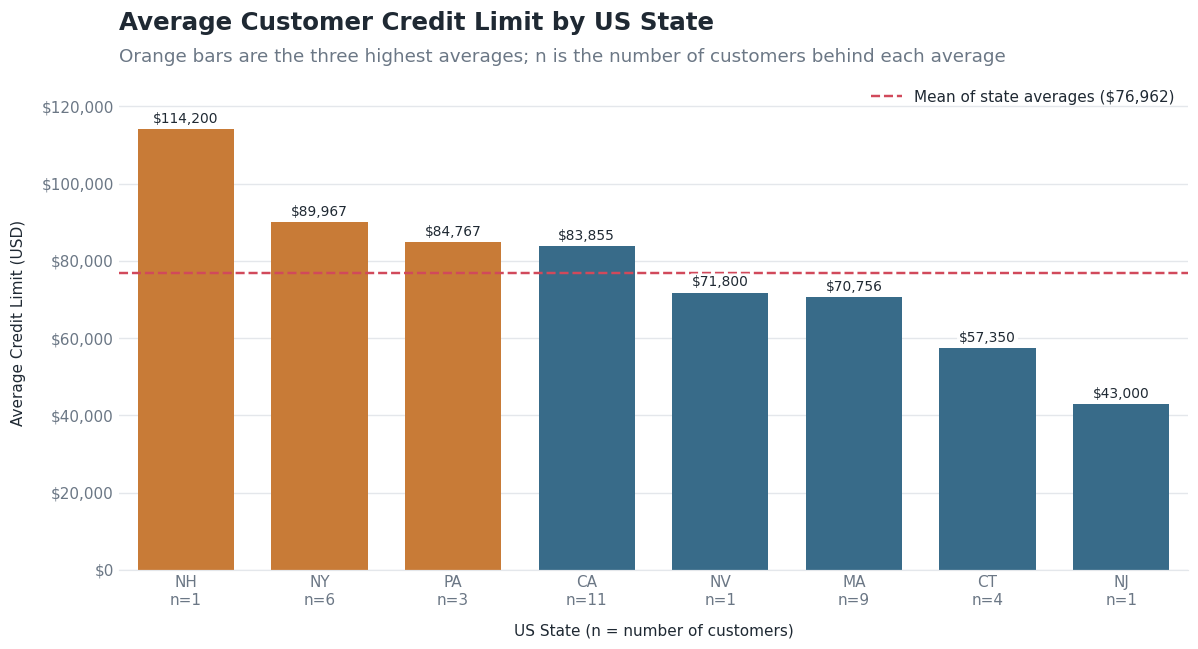

In [8]:
# Produce a visual to represent the average credit limit by state
overall_avg = df_avg_credit_by_state["avg_credit_limit"].mean()

# Show how many customers each average is based on (three states have only one customer)
plot_df = df_avg_credit_by_state.assign(
    state_label=df_avg_credit_by_state["state"] + "\nn=" + df_avg_credit_by_state["num_customers"].astype(str))

_ = bar_chart(
    plot_df, x="state_label", y="avg_credit_limit",
    title="Average Customer Credit Limit by US State",
    subtitle="Orange bars are the three highest averages; n is the number of customers behind each average",
    xlabel="US State (n = number of customers)", ylabel="Average Credit Limit (USD)",
    ref_line=overall_avg, ref_label=f"Mean of state averages ({money(overall_avg)})",
    name="step4_avg_credit_by_state",
)

> **Insight:**
> 
> The 36 US customers sit in only 8 states. New Hampshire has the highest average credit limit [\$114,200], but New Hampshire, Nevada [\$71,800] and New Jersey [\$43,000] each have a single customer, so those averages describe one account and should not drive policy on their own. Among states with several customers, New York [\$89,967, 6 customers], Pennsylvania [\$84,767, 3] and California [\$83,855, 11] lead, while Massachusetts [\$70,756, 9] and Connecticut [\$57,350, 4] are below the mean of state averages (\$76,962). Those two are the best candidates for a closer look at whether credit is too conservative or for growth campaigns, while New York, Pennsylvania and California (the multi-customer leaders) are the natural candidates for priority inventory allocation.

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [9]:
q5 = """
SELECT c.customerNumber,
       c.customerName,
       SUM(CAST(p.amount AS REAL)) AS total_payments
FROM customers c
JOIN payments p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
df_top_customers = pd.read_sql(q5, conn)
df_top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

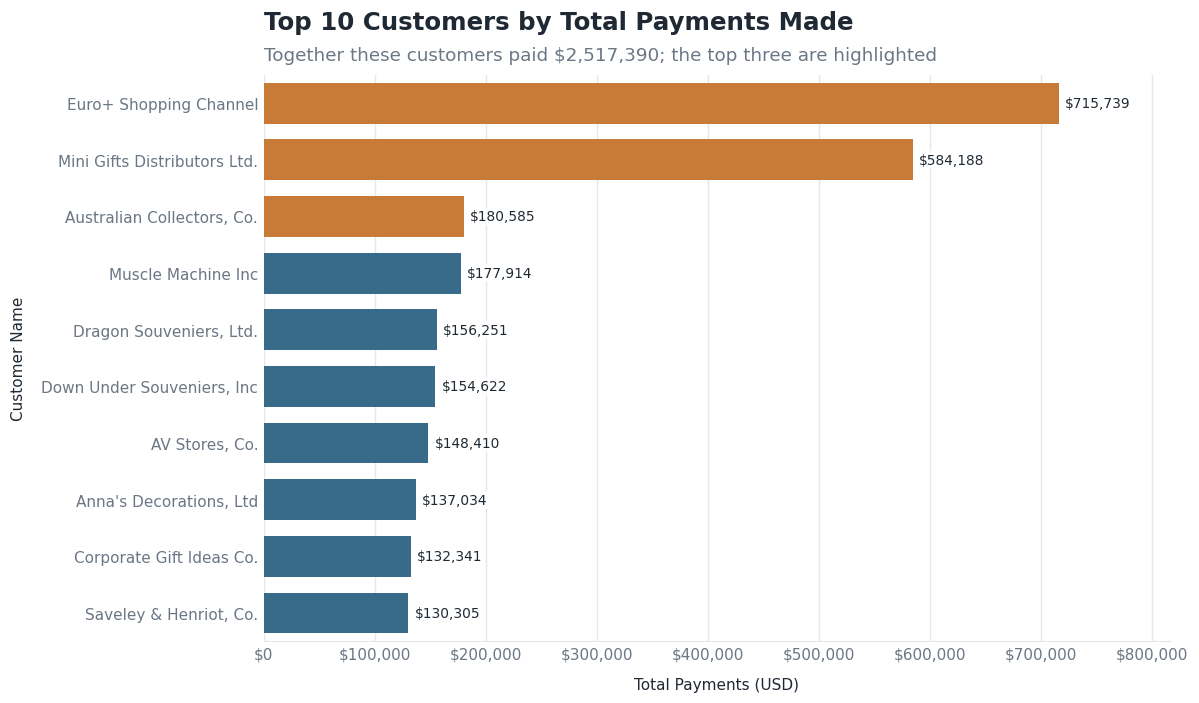

In [10]:
# Produce a visual to represent the top ten customers in terms of total payments
top_total = df_top_customers["total_payments"].sum()

_ = hbar_chart(
    df_top_customers, x="total_payments", y="customerName",
    title="Top 10 Customers by Total Payments Made",
    subtitle=f"Together these customers paid {money(top_total)}; the top three are highlighted",
    xlabel="Total Payments (USD)", ylabel="Customer Name",
    name="step5_top_customers",
)

**Insight:** 

Two customers stand out. Euro+ Shopping Channel ($715,739) and Mini Gifts Distributors Ltd. ($584,188) paid $1.30 million together, which is 51.6% of the top-10 total of $2.52 million, and each paid 3 to 4 times as much as the third-ranked customer (Australian Collectors, Co., $180,585). Ranks 3 to 10 are tightly bunched between $130,305 and $180,585. The two leaders deserve account-level, personalised thanks; the other eight form a close group. Three of the ten also appear in earlier lists: Mini Gifts and Corporate Gift Ideas Co. in the California target list (Step 2) and Australian Collectors in the collectable campaign (Step 3).

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [11]:
q6 = """
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(od.quantityOrdered) AS total_quantity_purchased
FROM customers c
JOIN orders o
  ON c.customerNumber = o.customerNumber
JOIN orderdetails od
  ON o.orderNumber = od.orderNumber
JOIN products p
  ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity_purchased ASC;
"""
df_customer_product_quantities = pd.read_sql(q6, conn)
df_customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


**Insight:** 2,531 customer-product combinations reach 10 or more units, from the minimum of 10 up to 308. The five largest all belong to Euro+ Shopping Channel (174 to 308 units): the 1992 Ferrari 360 Spider red (308), 1958 Chevy Corvette Limited Edition (245), 1970 Dodge Coronet (197), 1957 Chevy Pickup (183) and 2002 Chevy Corvette (174). Four are car models and one is a pickup truck, which suggests that classic car and pickup models are what this customer buys most, a useful lead for catalogue planning and sales-rep recommendations.

### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [12]:
q7 = """
SELECT p.productLine,
       COALESCE(SUM(od.quantityOrdered), 0) AS total_quantity_ordered,
       COUNT(DISTINCT p.productCode) AS number_of_products
FROM products p
LEFT JOIN orderdetails od
  ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
"""
df_product_line_analysis = pd.read_sql(q7, conn)
df_product_line_analysis

,productLine,total_quantity_ordered,number_of_products
0,Classic Cars,35582,38
1,Vintage Cars,22933,24
2,Motorcycles,12778,13
3,Planes,11872,12
4,Trucks and Buses,11001,11
5,Ships,8532,9
6,Trains,2818,3


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

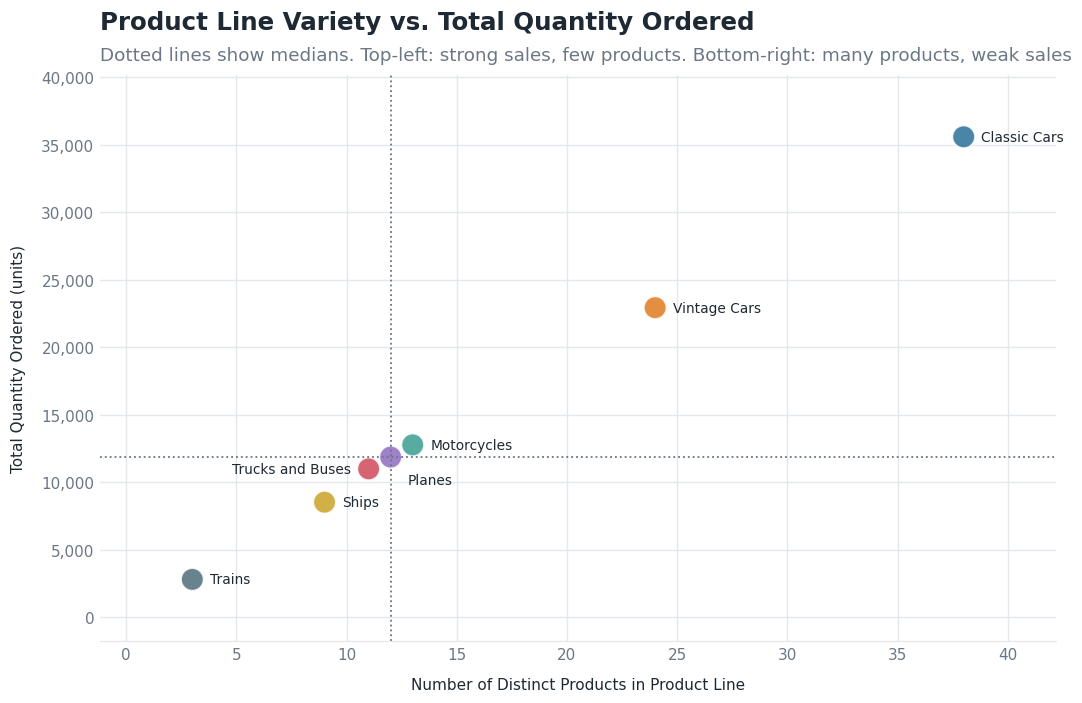

In [13]:
# Produce a visual to represent the the relation between number of products and the total amount ordered
_ = labeled_scatter(
    df_product_line_analysis, x="number_of_products", y="total_quantity_ordered",
    label="productLine", color_by="productLine",
    title="Product Line Variety vs. Total Quantity Ordered",
    subtitle="Dotted lines show medians. Top-left: strong sales, few products. Bottom-right: many products, weak sales",
    xlabel="Number of Distinct Products in Product Line",
    ylabel="Total Quantity Ordered (units)",
    y_fmt=thousands, name="step7_variety_vs_orders",
)

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

> Answer

I used a **scatter plot**. The question was whether product lines that offer more products also sell more units. That is a question about the relationship between two numbers, so each product line gets one dot, placed according to how many products it has (left to right) and how many units customers ordered from it (bottom to top). If more products really did lead to more orders, the dots would climb from the bottom left towards the top right. A bar chart would only let us compare one number at a time, and would hide that relationship.

I labelled each dot with its product line name so managers can see at a glance which line is which, and gave every line its own colour.

In the context of the question, the plot shows that variety and demand do move together: the seven dots sit almost on a straight line (correlation of about 1.00). Classic Cars has the most products (38) and the most units ordered (35,582); Trains has the fewest (3 products) and the fewest units (2,818).

The more useful reading is *why* they line up. Dividing units by the number of products gives almost the same figure for every line, between about 936 (Classic Cars) and 1,000 (Trucks and Buses) units per product. So a larger range does not dilute demand per product, but it does not raise it either: each product accounts for roughly 940 to 1,000 units. No line is a "many products, weak sales" case, and none punches far above its size. Classic Cars and Vintage Cars together account for 55.5% of all 105,516 units ordered, so they are where the volume is, while Trains and Ships are small mainly because their ranges are small. If the company wants more volume, widening the range of a line looks like a reasonable lever, as long as new products can match the historic 940 to 1,000 units each.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [14]:
q8 = """
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.email,
       o.officeCode,
       o.city AS office_city,
       o.country AS office_country,
       s.employeeNumber AS supervisorNumber,
       s.firstName AS supervisorFirstName,
       s.lastName AS supervisorLastName,
       s.jobTitle AS supervisorJobTitle
FROM employees e
JOIN offices o
  ON e.officeCode = o.officeCode
LEFT JOIN employees s
  ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY o.officeCode, e.lastName;
"""
df_remote_office_employees = pd.read_sql(q8, conn)
df_remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,office_city,office_country,supervisorNumber,supervisorFirstName,supervisorLastName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,1143,Anthony,Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,1143,Anthony,Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,1143,Anthony,Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,1143,Anthony,Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,1621,Mami,Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,1056,Mary,Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,1056,Mary,Patterson,VP Sales


**Result:** five offices have fewer than 5 employees, covering 12 employees: Boston (2), New York (2), Tokyo (2), Sydney (4) and London (2). All but one are Sales Reps; the exception is William Patterson, the Sales Manager (APAC) in Sydney. Supervisors for the transition: Anthony Bow (Sales Manager NA) for the four US employees, William Patterson for the three Sydney reps, Gerard Bondur for both London reps, and Mary Patterson (VP Sales) for William Patterson and Mami Nishi. Two details to check before reassigning people: Yoshimi Kato in Tokyo reports to Mami Nishi, who is a Sales Rep rather than a manager, and the job title "Sale Manager (EMEA)" is misspelled in the data.

## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

> Answer

The request had two layers: first work out **which offices** have fewer than 5 employees, then list **the employees** who work in those offices. The first layer depends on an aggregate (a headcount per office), and aggregates cannot be filtered in a `WHERE` clause, so it needs its own query.

The subquery does that: it groups the `employees` table by `officeCode`, counts the rows in each group, and uses `HAVING COUNT(*) < 5` to keep only the small offices. It returns just a list of office codes.

The outer query then uses `WHERE e.officeCode IN (subquery)` to keep only employees whose office appears in that list. I chose a subquery instead of hard-coding office codes because the result stays correct if staffing changes, and the headcount rule lives in one clear place. I joined `offices` for location details, and did a `LEFT JOIN` of `employees` to itself (aliased `s`) on `reportsTo = employeeNumber` to pull in each person's supervisor. A `LEFT JOIN` is used so that someone without a supervisor, such as the top executive, would still appear.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [15]:
# Close the connection
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [16]:
zip_file_path = 'data/im.db.zip'
extract_to_path = 'data/'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

conn4 = sqlite3.connect('data/im.db')
schema_df = pd.read_sql("""
SELECT * FROM sqlite_master;
""", conn4)

schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [17]:
# Begin your code here
# Part 2: Exploratory analysis of the IMDB movie database
# Rules: only movies with start_year <= 2019, and exclude null values.

# Look at the columns of the key tables
for tbl in ["movie_basics", "movie_ratings"]:
    print(tbl)
    print(pd.read_sql(f"PRAGMA table_info({tbl})", conn4)[["name", "type"]].to_string(index=False))
    print()

movie_basics
           name    type
       movie_id    TEXT
  primary_title    TEXT
 original_title    TEXT
     start_year INTEGER
runtime_minutes    REAL
         genres    TEXT

movie_ratings
         name    type
     movie_id    TEXT
averagerating    REAL
     numvotes INTEGER



### Initial exploration: scope of the data and missing values

In [18]:
# How many movies are there, and how many values are missing in each column?
df_scope = pd.read_sql("""
SELECT COUNT(*) AS total_movies,
       MIN(start_year) AS first_year,
       MAX(start_year) AS last_year,
       SUM(runtime_minutes IS NULL) AS missing_runtime,
       SUM(genres IS NULL) AS missing_genres
FROM movie_basics;
""", conn4)
df_scope

,total_movies,first_year,last_year,missing_runtime,missing_genres
0,146144,2010,2115,31739,5408


In [19]:
# Movies per release year (limited to 2010-2019, as instructed)
df_by_year = pd.read_sql("""
SELECT start_year, COUNT(*) AS num_movies
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
GROUP BY start_year
ORDER BY start_year;
""", conn4)
df_by_year

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [20]:
# Movies that have a rating, with genre and runtime (nulls excluded)
df_movies = pd.read_sql("""
SELECT mb.movie_id, mb.primary_title, mb.start_year, mb.runtime_minutes, mb.genres,
       mr.averagerating, mr.numvotes
FROM movie_basics mb
JOIN movie_ratings mr
  ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.runtime_minutes IS NOT NULL
  AND mb.genres IS NOT NULL
  AND mr.averagerating IS NOT NULL
  AND mr.numvotes IS NOT NULL;
""", conn4)
print(df_movies.shape)
df_movies[["runtime_minutes", "averagerating", "numvotes"]].describe()

(65720, 7)


,runtime_minutes,averagerating,numvotes
count,65720.000000,65720.000000,6.572000e+04
mean,94.732273,6.320902,3.954674e+03
std,209.377017,1.458878,3.208823e+04
min,3.000000,1.000000,5.000000e+00
25%,81.000000,5.500000,1.600000e+01
50%,91.000000,6.500000,6.200000e+01
75%,104.000000,7.300000,3.520000e+02
max,51420.000000,10.000000,1.841066e+06


In [21]:
# Extract Generes
df_genres = df_movies.assign(genre=df_movies["genres"].str.split(",")).explode("genre")

genre_summary = (df_genres.groupby("genre")
                 .agg(num_movies=("movie_id", "count"),
                      avg_rating=("averagerating", "mean"),
                      median_votes=("numvotes", "median"),
                      avg_runtime=("runtime_minutes", "mean"))
                 .reset_index())

# filter out generes
genre_summary = genre_summary[genre_summary["num_movies"] >= 100].sort_values("avg_rating", ascending=False)
genre_summary.round(2)

,genre,num_movies,avg_rating,median_votes,avg_runtime
7,Documentary,16423,7.32,21.0,85.77
17,News,575,7.28,19.0,78.27
4,Biography,3693,7.17,41.0,90.83
14,Music,1844,7.07,45.0,93.23
12,History,2704,7.05,40.0,92.61
22,Sport,1099,6.96,70.0,92.18
24,War,795,6.57,102.0,97.01
15,Musical,638,6.52,49.0,104.37
9,Family,3231,6.40,56.0,92.31
8,Drama,28394,6.39,85.0,98.43


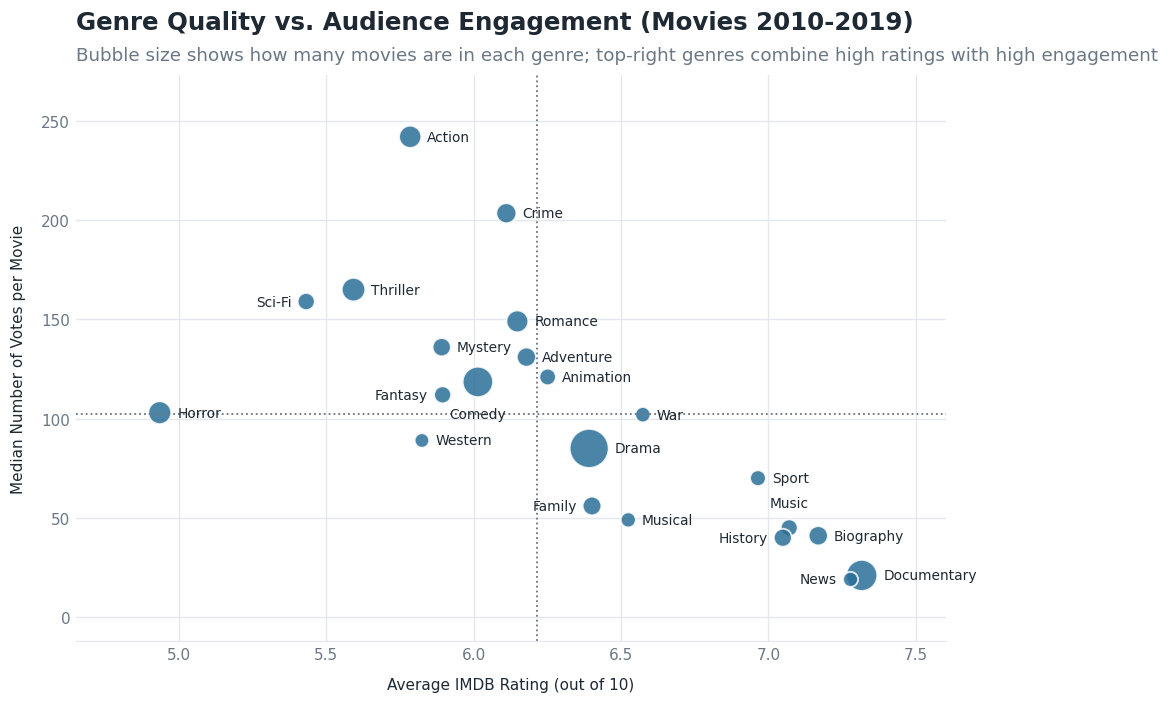

In [22]:
# audience rating vs. audience engagement by genre
_ = labeled_scatter(
    genre_summary, x="avg_rating", y="median_votes", label="genre", size="num_movies",
    title="Genre Quality vs. Audience Engagement (Movies 2010-2019)",
    subtitle="Bubble size shows how many movies are in each genre; top-right genres combine high ratings with high engagement",
    xlabel="Average IMDB Rating (out of 10)", ylabel="Median Number of Votes per Movie",
    y_fmt=thousands, name="part2_genre_quality_vs_engagement",
)

In [23]:
# Does a longer runtime go with a higher rating?
print("Correlation (runtime vs rating):",
      round(df_movies[["runtime_minutes", "averagerating"]].corr().iloc[0, 1], 3))

Correlation (runtime vs rating): -0.007


### Findings, business question and cleaning tasks (for the slides)

**Initial exploration findings**
- **Scope:** `movie_basics` holds 146,144 titles. 145,081 have a `start_year` from 2010 to 2019; the other 1,063 fall outside that range (the latest `start_year` is 2115, which is clearly wrong) and are excluded as instructed.
- **Release volume:** titles per year grow from 11,849 (2010) to a peak of 17,504 (2017) and dip to 16,849 in 2018. 2019 has only 8,379, about half of 2018, so 2019 looks incomplete rather than a real drop.
- **Missing data:** `runtime_minutes` is missing for 31,739 titles (21.7%) and `genres` for 5,408 (3.7%). Once movies are joined to their ratings and nulls are excluded, 65,720 movies remain (about 45% of those in range).
- **Ratings and votes:** the mean rating is 6.32 and the median 6.5 (scale 1 to 10). Votes are very skewed: the median movie has 62 votes, a quarter have 16 or fewer, and the maximum is 1.84 million. Many averages therefore rest on only a handful of votes.
- **Runtime:** the median is 91 minutes, but the range runs from 3 minutes to 51,420 minutes (about 857 hours), so there are extreme outliers. Runtime has no linear relationship with rating (correlation -0.007).
- **Genres (22 genres with at least 100 rated movies):** Drama (28,394), Documentary (16,423) and Comedy (15,514) are the biggest. The highest-rated genres are Documentary (7.32), News (7.28) and Biography (7.17); the lowest are Horror (4.93), Sci-Fi (5.43) and Thriller (5.59).
- **Ratings and engagement pull in opposite directions:** the genres with the most votes per movie are Action (median 242 votes), Crime (203.5) and Thriller (165), but the highest-rated genres have the fewest (News 19, Documentary 21, History 40). Across the 22 genres the correlation between average rating and median votes is -0.71. Animation (6.25, 121 votes) is the only genre above the median on both measures.

**Business question**
Among movies released from 2010 to 2019, which genres (and genre combinations) pair above-average audience ratings with strong audience engagement, once ratings based on very few votes are removed, and should a new studio prioritise those genres over the most-produced ones (Drama, Documentary, Comedy)?

**Potential data cleaning tasks**
1. Remove records with a `start_year` after 2019 (up to 2115) and treat 2019 as a partial year.
2. Handle nulls in `runtime_minutes` (31,739), `genres` (5,408) and movies with no rating by excluding them, not imputing.
3. Split the comma-separated `genres` column into one row per genre (normalisation); a movie then counts once per genre, so genre totals overlap.
4. Filter or cap `runtime_minutes` outliers (3 to 51,420 minutes) before analysing runtime.
5. Apply a minimum vote threshold (for example 100 votes) before comparing ratings, because the median movie has only 62 votes.
6. Check for duplicate movies and inconsistent title text (`primary_title` vs `original_title`, case and spacing) and confirm `movie_id` values match across tables.
